<a href="https://colab.research.google.com/github/nithinpalacherla-sys/Inventors/blob/main/CS2740_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 2740 — Homework 4

**Name:**  
**GTID:**  
**Due:** Sunday, October 11, 11:59pm

---

### Instructions

Run this notebook in **Google Colab**. Everything it uses is already installed there.

1. Fill in every cell marked `YOUR CODE HERE` and every written answer marked
   *Your answer here*. Double-click a text cell to edit it, and type math between
   dollar signs, for example `$u_1 = 13/16$`.
2. Cells marked *provided* run your code and draw the plots. You do not need to
   change them, but you do need to run them.
3. When you are done, run **Runtime → Restart and run all**.
4. Check your output before exporting. No cell output should be cut off, and
   every figure should fit on the page. Expand any output box that is still
   scrolling.
5. There are two submissions for this homework, one for the code and one for the
   written answers. Refer to the announcement for submission details.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# One random number generator for the whole notebook. The fixed seed means you
# get the same numbers every time you run it, which makes your write-up match
# your plots. Pass `rng` to the functions you write in Problems 2 and 3.
rng = np.random.default_rng(2740)


def plot_convergence(Ns, estimates, ylabel, title, xlabel="number of samples N (log scale)"):
    """Provided. Plot estimates against N on a log-scaled N axis."""
    plt.figure(figsize=(6, 4))
    plt.semilogx(Ns, estimates, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

---

# Problem 1 — Pseudo-Random Number Generation

A 6-bit XOR feedback shift register with the recurrence

$$b_i = b_{i-4} \oplus b_{i-6}, \qquad i \ge 6,$$

and the seed $(b_0, b_1, b_2, b_3, b_4, b_5) = (1, 1, 0, 1, 0, 0)$.

### (a) FSR bits and words

Compute $b_6$ through $b_{11}$ by hand, then group the first twelve bits into three 4-bit words and convert each word to a real number $u_i = w_i / 2^{\ell}$ with $\ell = 4$.

| $i$ | $b_{i-4}$ | $b_{i-6}$ | $b_i$ |
|---|---|---|---|
| 6 | 0 | 1 | 1 |
| 7 | 1 | 1 | 0 |
| 8 | 0 | 0 | 0 |
| 9 | 0 | 1 | 1 |
| 10 | 1 | 0 | 1 |
| 11 | 0 | 0 | 0 |

| Word | Bits | Decimal $w_i$ | $u_i = w_i/16$ |
|---|---|---|---|
| $w_1$ | 1101 | 13 | $13/16 = 0.1825$|
| $w_2$ | 0010 | 2 | $2/16 = 0.125$ |
| $w_3$ | 0110 | 6 | $6/16 = 0.375$|

### (b) Does the LCG have a full period?

For the LCG with $m = 16$, $a = 5$, $c = 3$, check all three conditions of the theorem and state your conclusion.

1. **$c$ and $m$ are relatively prime:** $\gcd(3, 16) = 1$. Satisfied.
2. **Every prime that divides $m$ also divides $a - 1$:** the only prime factor of $16$ is $2$, and $a - 1 = 4$ is divisible by $2$. Satisfied.
3. **If $4$ divides $m$, then $4$ divides $a - 1$:** $4$ divides $16$, and $4$ divides $a - 1 = 4$. Satisfied.

All three conditions hold, so the LCG has full period $m = 16$: starting from any $z_0$, it visits every value $0, 1, \dots, 15$ exactly once before repeating. Starting from $z_0 = 0$ the sequence is $0, 3, 2, 13, 4, 7, 6, 1, 8, 11, 10, 5, 12, 15, 14, 9$, then back to $0$.

### (c) Zero states

What happens to the FSR sequence if it reaches the state $(0,0,0,0,0,0)$? What happens to the LCG from part (b) if it reaches $z_i = 0$?

**FSR:** every new bit is the XOR of two earlier bits, and $0 \oplus 0 = 0$. If the register ever holds all zeros, every bit it generates after that is $0$, so it is stuck in the all-zero state forever and produces only zeros. This is why the all-zero state is excluded and a 6-bit register has at most $2^6 - 1 = 63$ usable states.

**LCG:** reaching $z_i = 0$ is not a problem, because $c = 3 \neq 0$. The next value is $z_{i+1} = (5 \cdot 0 + 3) \bmod 16 = 3$, so the sequence keeps going. Since the LCG has full period, $0$ is simply one of the 16 values in its cycle. (An LCG with $c = 0$ would get stuck at $0$, like the FSR.)


### Checking (a), (b), and (c) in code

Write three short functions and run the provided cell below them.

- `fsr_bits(seed, n)`: return the first `n` bits of the FSR sequence, starting with the six seed bits, using $b_i = b_{i-4} \oplus b_{i-6}$.
- `fsr_period(seed)`: return how many steps the register takes to return to a state it has already been in. A 6-bit register has at most $2^6 - 1 = 63$ nonzero states, so your answer must be at most 63.
- `lcg_period(m, a, c, z0)`: return the period of the LCG $z_{i+1} = (a z_i + c) \bmod m$, started at $z_0$.

In Python, `^` is XOR and `%` is the modulus operator.

In [2]:
SEED = [1, 1, 0, 1, 0, 0]


def fsr_bits(seed, n):
    """
    TODO: return a list of the first n bits of the sequence: the six seed bits
    followed by bits generated with b_i = b_{i-4} XOR b_{i-6}.
    """
    # YOUR CODE HERE:
    bits = list(seed)
    while len(bits) < n:
        i = len(bits)
        bits.append(bits[i - 4] ^ bits[i - 6])
    return bits[:n]



def fsr_period(seed):
    """
    TODO: run the register until its 6-bit state repeats one it has held
    before, and return the number of steps between the two visits.
    """
    # YOUR CODE HERE:
    bits = list(seed)
    seen = {tuple(bits): 0}
    step = 0
    while True:
        i = len(bits)
        bits.append(bits[i - 4] ^ bits[i - 6])
        step += 1
        state = tuple(bits[-6:])
        if state in seen:
            return step - seen[state]
        seen[state] = step


def lcg_period(m, a, c, z0):
    """
    TODO: run z -> (a*z + c) mod m until a value repeats, and return the period.
    """
    # YOUR CODE HERE:
    seen = {z0: 0}
    z = z0
    step = 0
    while True:
        z = (a * z + c) % m
        step += 1
        if z in seen:
            return step - seen[z]
        seen[z] = step



# Provided: compare these with your answers to (a), (b), and (c).
print("first 12 bits:", fsr_bits(SEED, 12), "  <- compare with part (a)")
print("FSR period:   ", fsr_period(SEED), "  (at most 63)")
print("LCG period:   ", lcg_period(16, 5, 3, 0), "  <- compare with part (b)")

first 12 bits: [1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0]   <- compare with part (a)
FSR period:    14   (at most 63)
LCG period:    16   <- compare with part (b)


The device is meant to run for a long time on these generated numbers. What does the FSR period you found say about using this register on its own?

*Your answer here.*

### (d) Tempering

Write `mini_temper(y)`, which takes a 16-bit integer and applies, in this order:

$$y \leftarrow y \oplus (y \gg 4), \qquad y \leftarrow y \oplus \big((y \ll 3)\ \&\ \texttt{0x6A50}\big), \qquad y \leftarrow y \oplus (y \gg 7).$$

In Python, `>>` and `<<` are the shift operators, `^` is XOR, and `&` is bitwise AND. Hexadecimal constants are written `0x6A50`.

Then enter your three words from part (a) in the provided cell below it and run it.

In [3]:
def mini_temper(y):
    """
    TODO: apply the three tempering steps to the 16-bit integer y and return
    the result.
    """
    # YOUR CODE HERE:
    y = y ^ (y >> 4)
    y = y ^ ((y << 3) & 0x6A50)
    y = y ^ (y >> 7)
    return y


# A first check: every step XORs y with something built from y, so tempering 0
# can only give 0 back.
print("mini_temper(0):", mini_temper(0), "  expected 0")

mini_temper(0): 0   expected 0


In [4]:
# Enter the three words you computed in part (a).
# YOUR CODE HERE:
WORDS = [13, 2, 6]

# Provided: runs your function on each word and prints the result.
if any(w is None for w in WORDS):
    print("Fill in WORDS with the three words from part (a).")
else:
    print(f"{'word':>6} {'bits':>6} {'tempered':>10}")
    for w in WORDS:
        print(f"{w:>6} {w:>04b} {mini_temper(w)!s:>10}")

  word   bits   tempered
    13 1101         77
     2 0010         18
     6 0110         22


---

# Problem 2 — Approximating an Area by Random Sampling

$$R = \{(x, y) \in \mathbb{R}^2 : x^2 + y^2 \le 1,\ x \ge 0,\ y \ge 0\}$$

### (a) Why sampling works

Explain why the area of $R$ can be approximated by sampling points uniformly from $[0,1] \times [0,1]$ and computing a ratio of counts.

The unit square has area $1$ and contains $R$. A point sampled uniformly from the square lands in $R$ with probability equal to the fraction of the square that $R$ covers, which is $\text{area}(R)/1 = \text{area}(R)$. So if $N_R$ of $N$ sampled points satisfy $x^2 + y^2 \le 1$, the ratio $N_R/N$ estimates this probability, and by the law of large numbers it approaches $\text{area}(R)$ as $N$ grows.

### (b) Estimate the area

Write `estimate_area(N, rng)`: sample $N$ points uniformly from $[0,1] \times [0,1]$, count how many land inside $R$, and return the estimated area.

`rng.random(size=(N, 2))` gives an $N \times 2$ array of uniform samples on $[0,1)$.

In [5]:
def estimate_area(N, rng):
    """
    TODO: sample N points uniformly from [0,1] x [0,1], count how many fall
    inside R, and return the estimated area of R.
    """
    # YOUR CODE HERE:
    points = rng.random(size=(N, 2))
    inside = points[:, 0]**2 + points[:, 1]**2 <= 1
    return np.count_nonzero(inside) / N


# Provided: runs your function at three sample sizes.
Ns_area = [10**2, 10**3, 10**4]
area_estimates = [estimate_area(N, rng) for N in Ns_area]

for N, est in zip(Ns_area, area_estimates):
    print(f"N = {N:>6}   estimated area = {est if est is None else round(est, 4)}")

N =    100   estimated area = 0.78
N =   1000   estimated area = 0.789
N =  10000   estimated area = 0.7839


### (c) Plot the estimates

Run the provided cell to plot your estimates against $N$ on a log-scaled $N$ axis.

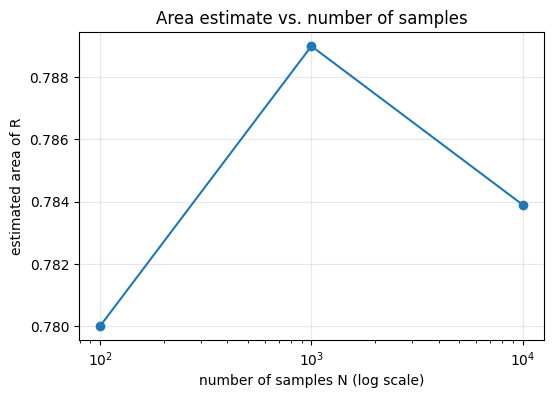

In [6]:
# Provided.
plot_convergence(Ns_area, area_estimates,
                 ylabel="estimated area of R",
                 title="Area estimate vs. number of samples")

### (d) Short answers

**(i)** What value does the estimate appear to converge to?

The estimates are $0.78$, $0.789$, and $0.7839$ for $N = 100$, $1000$, and $10000$. They approach about $0.785$, which is $\pi/4 \approx 0.7854$, the area of a quarter of the unit disk.

**(ii)** Why does increasing $N$ improve the estimate?

With few samples, random chance can make the fraction of hits noticeably too high or too low. With more samples, these fluctuations average out, and by the law of large numbers the fraction gets closer to the true probability. The typical error shrinks roughly like $1/\sqrt{N}$.

**(iii)** Give one example of a real-world quantity that could be estimated using a similar simulation.

The area of an irregularly shaped lake on a map: place the map inside a rectangle of known area, drop random points on it, and multiply the rectangle's area by the fraction of points that land on the lake.

---

# Problem 3 — Estimating an Expected Value by Simulation

Roll a fair six-sided die until a 6 appears. Let $X$ be the total number of rolls.

### (a) Why $X$ is a random variable

$X$ is a random variable because it is a number that depends on chance. We cannot know how many rolls it will take to get a 6 until we actually roll the die, and the answer can be different every time we repeat the experiment.

### (b) Estimate $E[X]$

Write two functions:

- `rolls_until_six(rng)`: simulate one run of the experiment and return the number of rolls it took.
- `estimate_expected_value(N, rng)`: run the experiment $N$ times and return the average number of rolls.

`rng.integers(1, 7)` returns a uniform random integer from 1 to 6.

In [9]:
def rolls_until_six(rng):
    """
    TODO: roll a fair six-sided die until a 6 appears, and return the number
    of rolls that took (counting the roll that produced the 6).
    """
    # YOUR CODE HERE:
    rolls = 0
    while True:
        rolls += 1
        if rng.integers(1, 7) == 6:
            return rolls


def estimate_expected_value(N, rng):
    """
    TODO: run rolls_until_six N times and return the average number of rolls.
    """
    # YOUR CODE HERE:
    count = 0
    for _ in range(N):
        count += rolls_until_six(rng)
    return count / N


# Provided: a quick check, then the estimates at five sample sizes.
first_runs = [rolls_until_six(rng) for _ in range(5)]
print("five single runs:", first_runs, "  (each should be an integer >= 1)\n")

Ns_rolls = [100, 500, 1000, 5000, 10000]
roll_estimates = [estimate_expected_value(N, rng) for N in Ns_rolls]

for N, est in zip(Ns_rolls, roll_estimates):
    print(f"N = {N:>6}   estimated E[X] = {est if est is None else round(est, 4)}")

five single runs: [14, 14, 4, 3, 13]   (each should be an integer >= 1)

N =    100   estimated E[X] = 5.16
N =    500   estimated E[X] = 6.132
N =   1000   estimated E[X] = 5.844
N =   5000   estimated E[X] = 6.103
N =  10000   estimated E[X] = 6.0912


### (c) Plot the estimates

Run the provided cell, then answer the question below it.

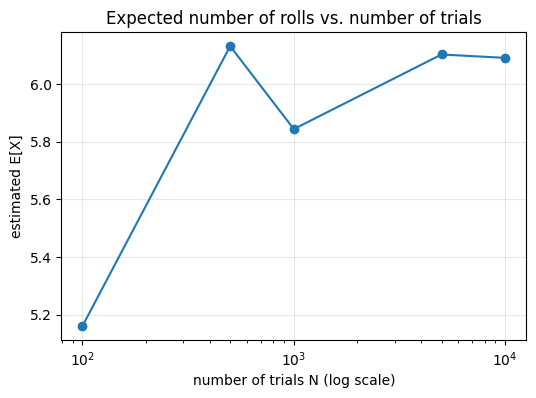

In [10]:
# Provided.
plot_convergence(Ns_rolls, roll_estimates,
                 ylabel="estimated E[X]",
                 title="Expected number of rolls vs. number of trials",
                 xlabel="number of trials N (log scale)")

What do you observe as $N$ increases?

As N increases, the estimated expected value gets closer and closer to 6, which is the expected value.

### (d) Why simulate?

Explain why simulation is useful here, even though this expectation could be computed analytically.

Simulation is useful because it lets us check our answer: if the simulated average comes out close to 6, it confirms both our math and our code are correct. Simulation also works in situations where the math is too hard to do by hand.